In [3]:
import re
import random
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import torch
import torch.nn as nn

from collections import Counter
from torch.utils.data import Dataset, DataLoader
from datasets import load_dataset
from sklearn.model_selection import train_test_split


#обираємо пристрій
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print('Пристрій:', device)


#завантажуємо датасет
ds = load_dataset('Helsinki-NLP/europarl', 'bg-de')

print(ds)
print(ds['train'][0])


#готуємо пари речень
raw_data = ds['train'].shuffle(seed=42).select(range(min(8000, len(ds['train']))))

pairs = []

for item in raw_data:
    bg = item['translation']['bg']
    de = item['translation']['de']

    if bg and de:
        pairs.append((bg, de))

print('Кількість пар:', len(pairs))


#токенізуємо текст
def tokenize(text):
    return re.findall(r'\w+|[^\w\s]', text.lower(), flags=re.UNICODE)


#розділяємо дані
train_pairs, val_pairs = train_test_split(pairs, test_size=0.1, random_state=42)

print('Навчальних пар:', len(train_pairs))
print('Валідаційних пар:', len(val_pairs))


#створюємо словники
PAD = '<pad>'
UNK = '<unk>'
BOS = '<bos>'
EOS = '<eos>'


def build_vocab(data, lang, max_vocab=12000):
    words = Counter()

    for pair in data:
        words.update(tokenize(pair[lang]))

    vocab = {PAD: 0, UNK: 1, BOS: 2, EOS: 3}

    for word, count in words.most_common(max_vocab - len(vocab)):
        vocab[word] = len(vocab)

    return vocab


vocab_bg = build_vocab(train_pairs, 0)
vocab_de = build_vocab(train_pairs, 1)

print('Розмір словника BG:', len(vocab_bg))
print('Розмір словника DE:', len(vocab_de))

Пристрій: cpu


/usr/local/lib/python3.13/dist-packages/huggingface_hub/utils/_auth.py:138: UserWarning: 
Error while fetching `HF_TOKEN` secret value from your vault: 'Requesting secret HF_TOKEN timed out. Secrets can only be fetched when running from the Colab UI.'.
  warnings.warn(f"\nError while fetching `HF_TOKEN` secret value from your vault: '{str(e)}'.")


README.md:   0%|          | 0.00/76.3k [00:00<?, ?B/s]

bg-de/train-00000-of-00001.parquet: reconstructing file:   0%|          |  0.00B / 87.3MB            

bg-de/train-00000-of-00001.parquet: downloading bytes:           |  0.00B            

Generating train split:   0%|          | 0/393298 [00:00<?, ? examples/s]

DatasetDict({
    train: Dataset({
        features: ['translation'],
        num_rows: 393298
    })
})
{'translation': {'bg': 'Състав на Парламента: вж. протоколи', 'de': 'Zusammensetzung des Parlaments: siehe Protokoll'}}
Кількість пар: 8000
Навчальних пар: 7200
Валідаційних пар: 800
Розмір словника BG: 12000
Розмір словника DE: 12000


In [4]:
#перетворюємо речення у числа
max_len = 20


def encode_text(text, vocab):
    tokens = tokenize(text)[:max_len]
    ids = [vocab[BOS]]

    for word in tokens:
        ids.append(vocab.get(word, vocab[UNK]))

    ids.append(vocab[EOS])

    return ids


class TranslationDataset(Dataset):
    def __init__(self, data):
        self.data = data

    def __len__(self):
        return len(self.data)

    def __getitem__(self, index):
        bg, de = self.data[index]

        bg_ids = encode_text(bg, vocab_bg)
        de_ids = encode_text(de, vocab_de)

        return torch.tensor(bg_ids), torch.tensor(de_ids)


#додаємо padding до речень
def collate_fn(batch):
    bg_batch, de_batch = zip(*batch)

    bg_batch = nn.utils.rnn.pad_sequence(bg_batch, batch_first=True, padding_value=0)
    de_batch = nn.utils.rnn.pad_sequence(de_batch, batch_first=True, padding_value=0)

    return bg_batch, de_batch


train_data = TranslationDataset(train_pairs)
val_data = TranslationDataset(val_pairs)

train_loader = DataLoader(train_data, batch_size=32, shuffle=True, collate_fn=collate_fn)
val_loader = DataLoader(val_data, batch_size=32, shuffle=False, collate_fn=collate_fn)


#створюємо енкодер
class Encoder(nn.Module):
    def __init__(self, input_size, embedding_size, hidden_size):
        super().__init__()

        self.embedding = nn.Embedding(input_size, embedding_size, padding_idx=0)
        self.gru = nn.GRU(embedding_size, hidden_size, batch_first=True)

    def forward(self, x):
        embedded = self.embedding(x)
        outputs, hidden = self.gru(embedded)

        return outputs, hidden


#створюємо декодер з увагою
class Decoder(nn.Module):
    def __init__(self, output_size, embedding_size, hidden_size):
        super().__init__()

        self.embedding = nn.Embedding(output_size, embedding_size, padding_idx=0)
        self.gru = nn.GRU(embedding_size + hidden_size, hidden_size, batch_first=True)

        self.fc = nn.Linear(hidden_size * 2 + embedding_size, output_size)

    def forward_step(self, x, hidden, encoder_outputs, src_mask):
        embedded = self.embedding(x).unsqueeze(1)

        scores = torch.bmm(encoder_outputs, hidden[-1].unsqueeze(2)).squeeze(2)
        scores = scores.masked_fill(src_mask == 0, -1e9)

        attention = torch.softmax(scores, dim=1)

        context = torch.bmm(attention.unsqueeze(1), encoder_outputs)

        gru_input = torch.cat((embedded, context), dim=2)
        output, hidden = self.gru(gru_input, hidden)

        output = torch.cat((output.squeeze(1), context.squeeze(1), embedded.squeeze(1)), dim=1)
        prediction = self.fc(output)

        return prediction, hidden, attention


#об'єднуємо енкодер і декодер
class Seq2Seq(nn.Module):
    def __init__(self, encoder, decoder):
        super().__init__()

        self.encoder = encoder
        self.decoder = decoder

    def forward(self, src, trg, teacher_forcing=0.5):
        batch_size = src.shape[0]
        trg_len = trg.shape[1]

        outputs = torch.zeros(batch_size, trg_len, len(vocab_de, ), device=device)
        encoder_outputs, hidden = self.encoder(src)

        src_mask = (src != 0).float()
        x = trg[:, 0]

        attentions = []

        for t in range(1, trg_len):
            prediction, hidden, attention = self.decoder.forward_step(x, hidden, encoder_outputs, src_mask)

            outputs[:, t, :] = prediction
            attentions.append(attention)

            if random.random() < teacher_forcing:
                x = trg[:, t]
            else:
                x = prediction.argmax(1)

        return outputs, attentions


embedding_size = 128
hidden_size = 128

encoder = Encoder(len(vocab_bg), embedding_size, hidden_size)
decoder = Decoder(len(vocab_de), embedding_size, hidden_size)

model = Seq2Seq(encoder, decoder).to(device)

print(model)

Seq2Seq(
  (encoder): Encoder(
    (embedding): Embedding(12000, 128, padding_idx=0)
    (gru): GRU(128, 128, batch_first=True)
  )
  (decoder): Decoder(
    (embedding): Embedding(12000, 128, padding_idx=0)
    (gru): GRU(256, 128, batch_first=True)
    (fc): Linear(in_features=384, out_features=12000, bias=True)
  )
)


Епоха 1/3 | Train Loss: 6.3938 | Val Loss: 5.9498
Епоха 2/3 | Train Loss: 5.6933 | Val Loss: 5.8358
Епоха 3/3 | Train Loss: 5.3471 | Val Loss: 5.7424


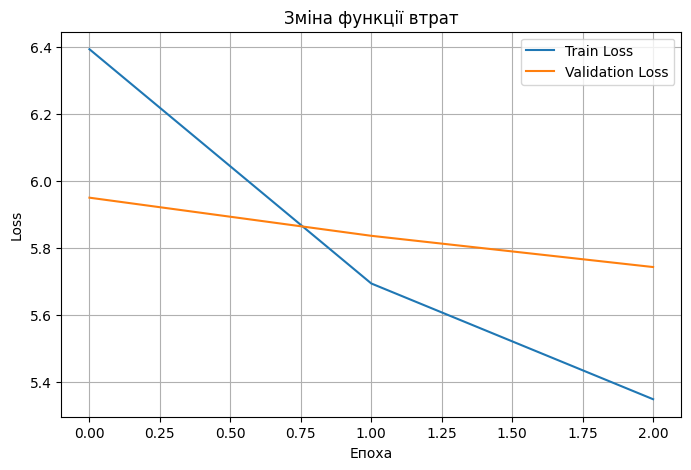

In [5]:
#налаштовуємо навчання
criterion = nn.CrossEntropyLoss(ignore_index=0)
optimizer = torch.optim.Adam(model.parameters(), lr=0.001)

epochs = 3
train_losses = []
val_losses = []


#навчання на одній епосі
def train_epoch(model, loader):
    model.train()
    total_loss = 0

    for bg, de in loader:
        bg = bg.to(device)
        de = de.to(device)

        optimizer.zero_grad()

        output, _ = model(bg, de, teacher_forcing=0.5)

        output = output[:, 1:, :].reshape(-1, len(vocab_de))
        target = de[:, 1:].reshape(-1)

        loss = criterion(output, target)
        loss.backward()

        torch.nn.utils.clip_grad_norm_(model.parameters(), 1.0)

        optimizer.step()

        total_loss += loss.item()

    return total_loss / len(loader)


#перевіряємо модель на валідаційних даних
def evaluate(model, loader):
    model.eval()
    total_loss = 0

    with torch.no_grad():
        for bg, de in loader:
            bg = bg.to(device)
            de = de.to(device)

            output, _ = model(bg, de, teacher_forcing=0)

            output = output[:, 1:, :].reshape(-1, len(vocab_de))
            target = de[:, 1:].reshape(-1)

            loss = criterion(output, target)
            total_loss += loss.item()

    return total_loss / len(loader)


#запускаємо навчання
for epoch in range(epochs):
    train_loss = train_epoch(model, train_loader)
    val_loss = evaluate(model, val_loader)

    train_losses.append(train_loss)
    val_losses.append(val_loss)

    print(f'Епоха {epoch + 1}/{epochs} | Train Loss: {train_loss:.4f} | Val Loss: {val_loss:.4f}')


#малюємо графік
plt.figure(figsize=(8, 5))

plt.plot(train_losses, label='Train Loss')
plt.plot(val_losses, label='Validation Loss')

plt.xlabel('Епоха')
plt.ylabel('Loss')
plt.title('Зміна функції втрат')
plt.legend()
plt.grid()
plt.show()

Болгарською: Затова се обръщам към Комисията, която е длъжна да не взема страна, а да сформира политически алианс с Европейския парламент, за да може алиансът на народите да гарантира, че можем да мечтаем за онова, което желаем за Европейския съюз - Съюз на народите.
Еталонний переклад: So baue ich auf die Kommission, die keine Partei ergreifen, sondern eine politische Allianz mit dem Europäischen Parlament bilden sollte, damit die Allianz der Völker sicherstellt, dass wir von dem träumen können, was wir für diese Europäische Union, die Union der Völker, wünschen.
Переклад моделі: ich möchte ich , , , , , , , , , , die , die <unk> ,
------------------------------------------------------------
Болгарською: Ето кое е важното: програмата, която кандидатът представя, тази която той представя сега в общите й черти, след това подробната програма, която ще бъде представена към края на годината, надявам се, когато Комисията бъде съставена.
Еталонний переклад: Folgendes zählt: Das Programm, das

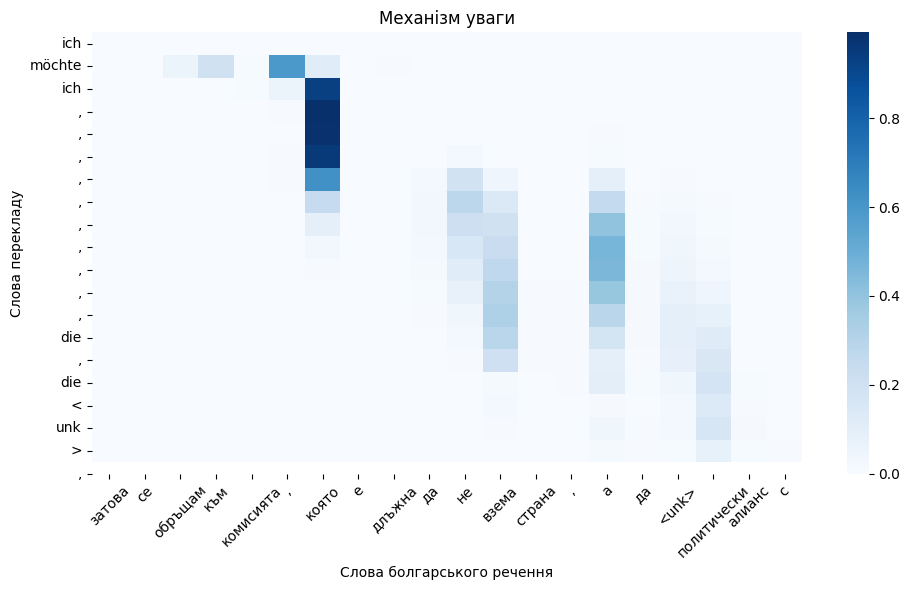

In [6]:
#створюємо зворотний словник
reverse_de = {index: word for word, index in vocab_de.items()}


#функція перекладу
def translate(sentence):
    model.eval()

    src_ids = encode_text(sentence, vocab_bg)
    src = torch.tensor([src_ids], device=device)

    with torch.no_grad():
        encoder_outputs, hidden = model.encoder(src)

        src_mask = (src != 0).float()
        x = torch.tensor([vocab_de[BOS]], device=device)

        result = []
        attention_list = []

        for _ in range(max_len + 2):
            prediction, hidden, attention = model.decoder.forward_step(
                x, hidden, encoder_outputs, src_mask
            )

            next_word = prediction.argmax(1).item()
            attention_list.append(attention[0].cpu().numpy())

            if next_word == vocab_de[EOS]:
                break

            if next_word not in [vocab_de[BOS], vocab_de[PAD]]:
                result.append(reverse_de.get(next_word, UNK))

            x = torch.tensor([next_word], device=device)

    return ' '.join(result), np.array(attention_list), src_ids


#перевіряємо кілька речень
for bg, de in val_pairs[:5]:
    prediction, attention, src_ids = translate(bg)

    print('Болгарською:', bg)
    print('Еталонний переклад:', de)
    print('Переклад моделі:', prediction)
    print('-' * 60)


#дивимося на увагу моделі
bg, de = val_pairs[0]
prediction, attention, src_ids = translate(bg)

source_words = [reverse_word for reverse_word in [
    {value: key for key, value in vocab_bg.items()}.get(i, UNK) for i in src_ids
]][1:-1]

target_words = tokenize(prediction)

if len(target_words) > 0 and attention.size > 0:
    attention = attention[:len(target_words), :len(source_words)]

    plt.figure(figsize=(10, 6))

    sns.heatmap(
        attention,
        xticklabels=source_words,
        yticklabels=target_words,
        cmap='Blues'
    )

    plt.xlabel('Слова болгарського речення')
    plt.ylabel('Слова перекладу')
    plt.title('Механізм уваги')
    plt.xticks(rotation=45)
    plt.tight_layout()
    plt.show()